<a href="https://colab.research.google.com/github/serennnn4/Fundamentos-Machine-Learning/blob/main/PA2_3018.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Caso: Organización del laboratorio LIBIPMET**


---


### Fundamentos de Machine Learning | Proceso de Aprendizaje II
##### Por: María Fernanda León Catalán

**Problemática:** Se busca entrenar un modelo no supervisado de clustering (K-Means) para poder agrupar compuestos químicos desde las proposiciones fisicoquímicas, determinando el número óptimo de grupos. Una vez se obtenga dicho modelo, se exportará para su uso.

Dicho trabajo se presentará a través del proceso analítico EDA.



---




### **Primera fase: Recolección de datos**
##### Se importarán las librerías y después se cargará el dataset.



In [65]:
##Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno


from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import joblib


In [66]:
##Carga de dataset

url="https://raw.githubusercontent.com/inefable12/inteligencia_molecular/refs/heads/main/SESION_2/dataset_PA2.csv"
df=pd.read_csv(url)


##Resumen del dataset
df.head().style.set_caption("Resumen")

,smiles,validacion,NumAtomPesados,h_implicitos,coef_de_part,MM,TPSA
0,C(CCl)Cl,0,4,4,1.464000,98.960000,74.775745
1,C(CO)O,0,4,6,-1.029000,62.068000,40.460000
2,CC(=O)C,0,4,6,0.595300,58.080000,17.070000
3,CCCCO,0,5,10,0.778800,74.123000,20.230000
4,Cl,0,1,1,0.421800,36.461000,74.775745


### **Segunda fase: Limpieza de datos**
##### Se evaluará la integridad y se realizará la limpieza respectiva.


In [67]:
#Revisión Integridad
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   smiles          140 non-null    object 
 1   validacion      140 non-null    int64  
 2   NumAtomPesados  140 non-null    int64  
 3   h_implicitos    140 non-null    int64  
 4   coef_de_part    140 non-null    float64
 5   MM              140 non-null    float64
 6   TPSA            140 non-null    float64
dtypes: float64(3), int64(3), object(1)
memory usage: 7.8+ KB


#####Conclusión: Con la ejecución del código, se evidencia que contamos con con 140 moléculas para trabajar en los 7 atributos. Además, no contamos con datos nulos.


In [68]:
# La columna validacion con valor 0, significa que la representación smiles es
# correcta.

#Revisión columna "Validación" = 0
(df['validacion'] == 0).sum()



np.int64(140)

#####Conclusión: Se verificó que los 140 registros cumplen la condición de validación == 0, por lo que no fue necesario descartar filas.



---
### **Preprocesamiento**


---




In [69]:
# Separamos las columnnas de identificación (Smiles, Validacion)
# de columnas numéricas (NumAtomPesados, h_implicitos,
#coef_de_part, MM, TPSA) que se usarán para el clustering.

df_id=df[['smiles','validacion']]
df_numerica=df[['NumAtomPesados','h_implicitos','coef_de_part','MM','TPSA']]

df_numerica.head().style.set_caption("ResumenSeparacion")

,NumAtomPesados,h_implicitos,coef_de_part,MM,TPSA
0,4,4,1.464000,98.960000,74.775745
1,4,6,-1.029000,62.068000,40.460000
2,4,6,0.595300,58.080000,17.070000
3,5,10,0.778800,74.123000,20.230000
4,1,1,0.421800,36.461000,74.775745


In [70]:
# Se eliminará algún atributo con correlación de Pearson > 0.9 de ser
# necesario.

df_numerica.corr(method='pearson')

,NumAtomPesados,h_implicitos,coef_de_part,MM,TPSA
NumAtomPesados,1.000000,0.878918,0.647949,0.983952,0.616025
h_implicitos,0.878918,1.000000,0.785084,0.862607,0.370809
coef_de_part,0.647949,0.785084,1.000000,0.644347,-0.060621
MM,0.983952,0.862607,0.644347,1.000000,0.617019
TPSA,0.616025,0.370809,-0.060621,0.617019,1.000000


In [71]:
# Al encontrar una correlación >0.9 entre:
# NumAtomPesados y MM, decidimos mantener MM
# ya que cuenta con mayor información realista
#sobre el tamaño y la masa de cada molécula.

df_numerica=df_numerica.drop(columns=['NumAtomPesados'])

#Visualización del descarte de columna.
df_numerica.head().style.set_caption("Resumen Descarte de Columna NumAtomPesado")

,h_implicitos,coef_de_part,MM,TPSA
0,4,1.464000,98.960000,74.775745
1,6,-1.029000,62.068000,40.460000
2,6,0.595300,58.080000,17.070000
3,10,0.778800,74.123000,20.230000
4,1,0.421800,36.461000,74.775745


In [72]:
# Aplicaremos la estandarización/normalización a las variables numéricas.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_numerica)


#Visualización
df_scaled = pd.DataFrame(X_scaled, columns=df_numerica.columns)
df_scaled.head().style.set_caption("Resumen Estandarización")

,h_implicitos,coef_de_part,MM,TPSA
0,-1.010611,-0.732542,-1.121159,-0.088494
1,-0.923917,-1.398574,-1.276287,-0.666812
2,-0.923917,-0.964625,-1.293056,-1.061000
3,-0.750528,-0.915601,-1.225597,-1.007745
4,-1.140653,-1.010977,-1.383963,-0.088494




---


### **Tercera fase: Implementación de modelo**
##### Selección de K de acuerdo a la inercia y cohesión

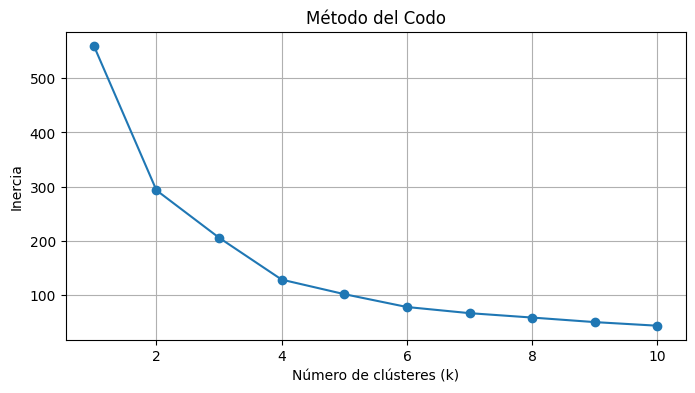

In [73]:
#Rango de grupos para evaluar la Inercia.
inercia = []
k_value_elbow= range(1,11)


for k in k_value_elbow:
  kmeans = KMeans(n_clusters=k, random_state=42,n_init=10)
  kmeans.fit(df_scaled)
  inercia.append(kmeans.inertia_)

#Visualización del Diagrama del Codo
plt.figure(figsize=(8, 4))
plt.plot(k_value_elbow, inercia, marker='o')
plt.title('Método del Codo')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()




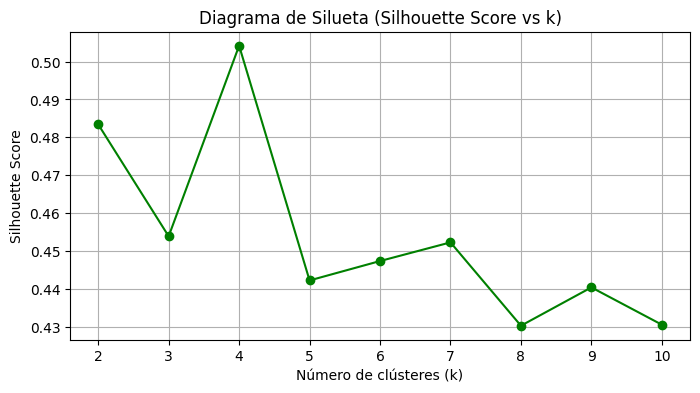

In [78]:
#Rango de grupos para evaluar la Cohesión y Separación.
silueta = []
k_value_sil= range(2,11)


for k in k_value_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, etiquetas)
    silueta.append(score)

#Visualización del Diagrama de la Silueta
plt.figure(figsize=(8, 4))
plt.plot(k_value_sil, silueta, marker='o', color='green')
plt.title('Diagrama de Silueta (Silhouette Score vs k)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

####Conclusión: Se seleccionó K = 4 como el número óptimo de clústeres debido a la concordancia entre ambos criterios.

####En el diagrama del codo representa el punto de inflexión donde la inercia reduce su tasa de disminución; mientras tanto, en el análisis de silueta, K = 4 maximiza el coeficiente medio de silueta, garantizando clústeres compactos y bien diferenciados entre sí,



---


### **Cuarta Fase: Análisis**
##### Conclusiones sobre el tipo de moléculas agrupadas.

In [ ]:
# Cálculo de media x clúster
perfil_clusters = df_resultado.groupby('cluster').mean()
perfil_clusters